In [9]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 15

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [10]:
print(os.listdir("/kaggle/input"))

['datasets']


In [11]:
import os

TRAIN_DIR = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training"
TEST_DIR = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing"

print("Training classes:", os.listdir(TRAIN_DIR))
print("Testing classes:", os.listdir(TEST_DIR))

Training classes: ['pituitary', 'notumor', 'meningioma', 'glioma']
Testing classes: ['pituitary', 'notumor', 'meningioma', 'glioma']


In [12]:

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

assert test_ds.class_names == class_names, "Class order mismatch!"

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_dataset(ds):
    return ds.map(
        lambda x, y: (preprocess_input(x), y),
        num_parallel_calls=AUTOTUNE
    ).prefetch(AUTOTUNE)

train_ds = preprocess_dataset(train_ds)
val_ds = preprocess_dataset(val_ds)
test_ds = preprocess_dataset(test_ds)


Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


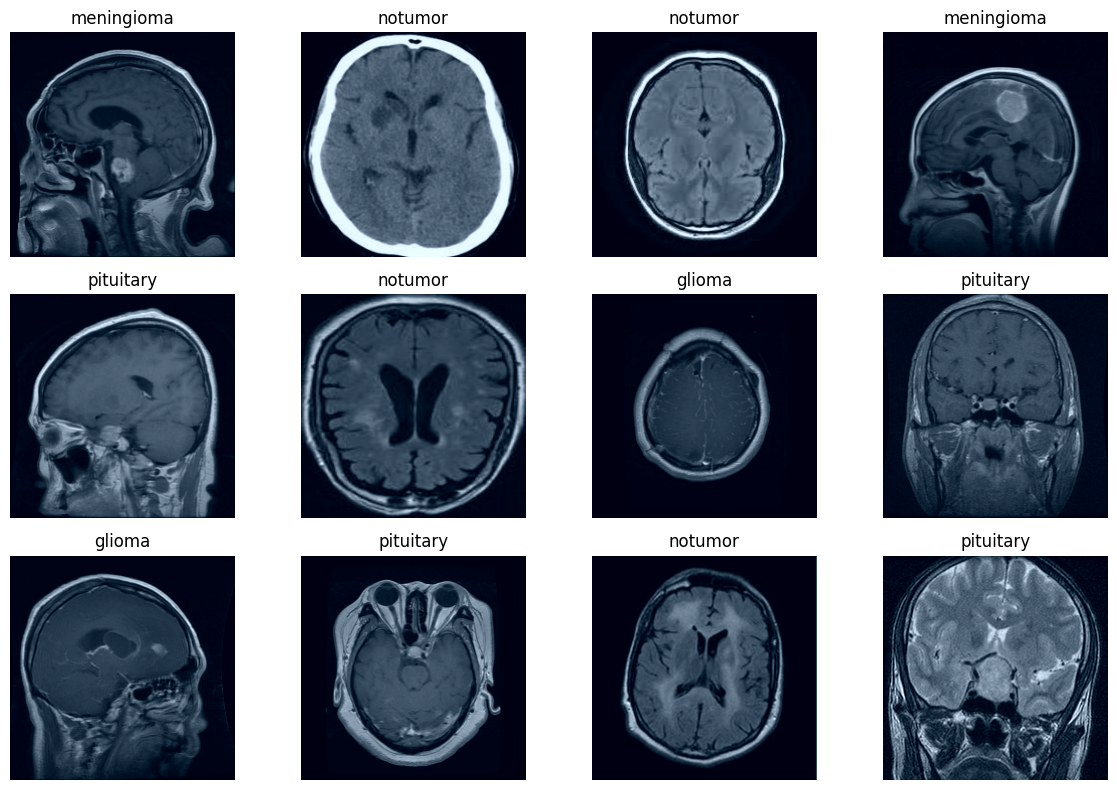

In [13]:

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)

        # Reverse VGG16 preprocessing for display
        img = images[i].numpy()
        img = img[..., ::-1] + [103.939, 116.779, 123.68]
        img = np.clip(img, 0, 255).astype("uint8")

        plt.imshow(img)
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [14]:

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained convolutional layers
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

# Data augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)

# VGG16 feature extraction
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,044 (56.64 MB)

 Trainable params: 132,356 (517.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [15]:

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),

    keras.callbacks.ModelCheckpoint(
        "best_vgg16_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 183ms/step - accuracy: 0.4281 - loss: 2.6718 - val_accuracy: 0.7920 - val_loss: 0.5857 - learning_rate: 1.0000e-04
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 183ms/step - accuracy: 0.6609 - loss: 1.0801 - val_accuracy: 0.8366 - val_loss: 0.4394 - learning_rate: 1.0000e-04
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.7397 - loss: 0.7580 - val_accuracy: 0.8562 - val_loss: 0.3847 - learning_rate: 1.0000e-04
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.7717 - loss: 0.6229 - val_accuracy: 0.8732 - val_loss: 0.3510 - learning_rate: 1.0000e-04
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.7946 - loss: 0.5474 - val_accuracy: 0.8786 - val_loss: 0.3342 - learning_rate: 1.0000e-04
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.8232 - loss: 0.4927 - val_accuracy: 0.8884 - val_loss: 0.3121 - learning_rate: 1.0000e-04
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 18

In [16]:

base_model.trainable = True

# Freeze all layers except block5
for layer in base_model.layers:
    if not layer.name.startswith("block5"):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)



Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 32s 207ms/step - accuracy: 0.8955 - loss: 0.2960 - val_accuracy: 0.9357 - val_loss: 0.1806 - learning_rate: 1.0000e-05
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 209ms/step - accuracy: 0.9183 - loss: 0.2189 - val_accuracy: 0.9500 - val_loss: 0.1536 - learning_rate: 1.0000e-05
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 203ms/step - accuracy: 0.9308 - loss: 0.1854 - val_accuracy: 0.9509 - val_loss: 0.1373 - learning_rate: 1.0000e-05
Epoch 4/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 207ms/step - accuracy: 0.9493 - loss: 0.1444 - val_accuracy: 0.9589 - val_loss: 0.1205 - learning_rate: 1.0000e-05
Epoch 5/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 205ms/step - accuracy: 0.9500 - loss: 0.1327 - val_accuracy: 0.9580 - val_loss: 0.1137 - learning_rate: 1.0000e-05
Epoch 6/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 202ms/step - accuracy: 0.9647 - loss: 0.1041 - val_accuracy: 0.9616 - val_loss: 0.1259 - learning_rate: 1.0000e-05
Epoch 7/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 206ms/ste

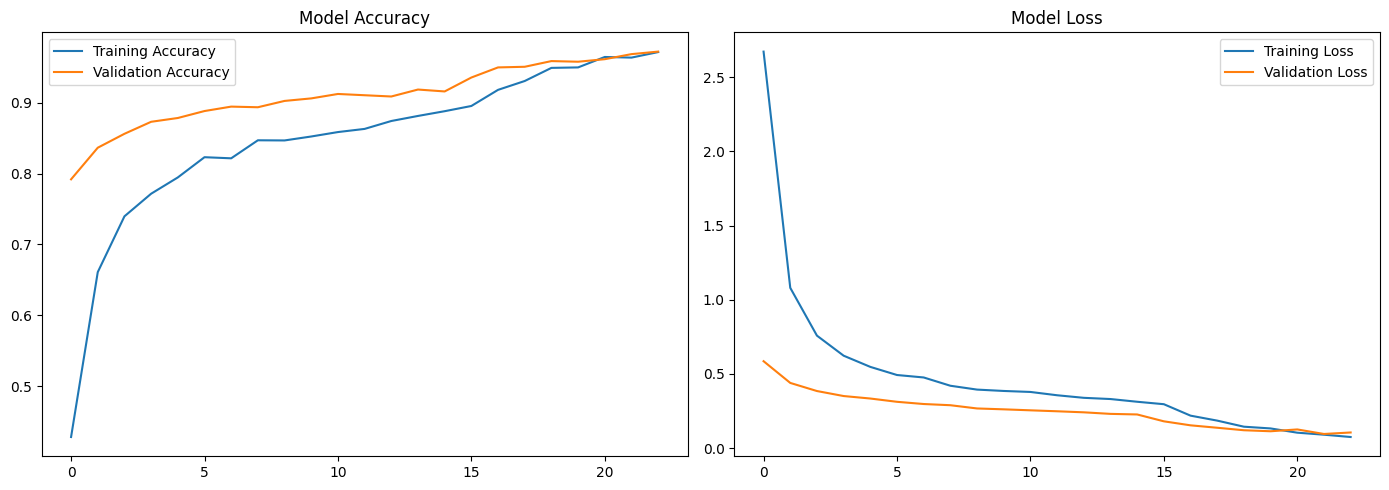

In [17]:

acc = history.history["accuracy"] + fine_history.history["accuracy"]
val_acc = history.history["val_accuracy"] + fine_history.history["val_accuracy"]

loss = history.history["loss"] + fine_history.history["loss"]
val_loss = history.history["val_loss"] + fine_history.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(acc, label="Training Accuracy")
axes[0].plot(val_acc, label="Validation Accuracy")
axes[0].set_title("Model Accuracy")
axes[0].legend()

axes[1].plot(loss, label="Training Loss")
axes[1].plot(val_loss, label="Validation Loss")
axes[1].set_title("Model Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_history.png", dpi=150)
plt.show()


In [18]:

# Load the best checkpoint
model = keras.models.load_model("best_vgg16_model.keras")

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_probs = model.predict(test_ds)
y_pred = np.argmax(y_probs, axis=1)

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))


50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 134ms/step - accuracy: 0.9275 - loss: 0.4837
Test Loss: 0.4837
Test Accuracy: 0.9275
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 138ms/step

Classification Report:

              precision    recall  f1-score   support

      glioma     0.9873    0.7775    0.8699       400
  meningioma     0.8824    0.9375    0.9091       400
     notumor     0.8869    1.0000    0.9401       400
   pituitary     0.9731    0.9950    0.9839       400

    accuracy                         0.9275      1600
   macro avg     0.9324    0.9275    0.9258      1600
weighted avg     0.9324    0.9275    0.9258      1600



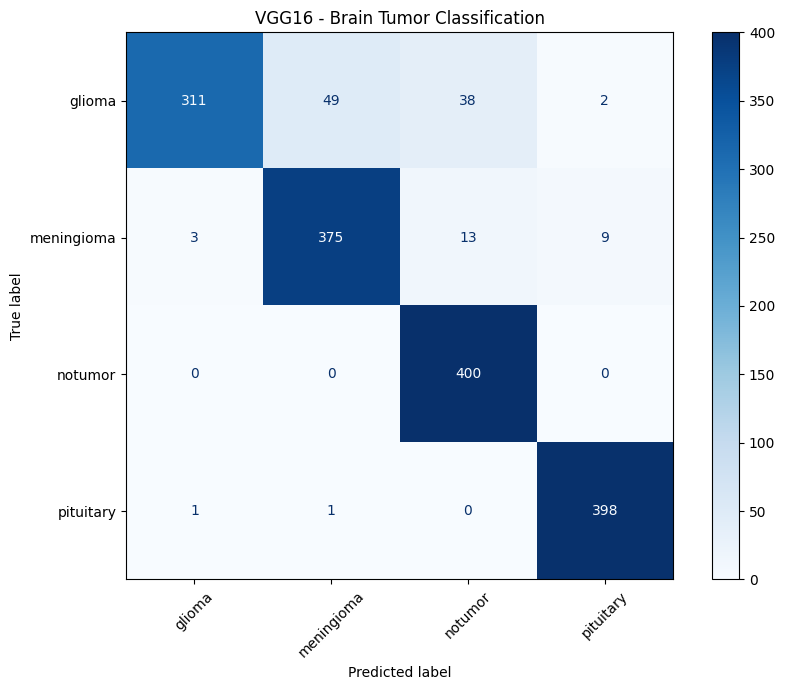

In [19]:

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)

plt.title("VGG16 - Brain Tumor Classification")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()


In [20]:

model.save("brain_tumor_vgg16.keras")

print("Model saved successfully!")


Model saved successfully!


In [21]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Recreate the SAME train/validation split
train_raw = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_raw = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_raw = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)

print("Classes:", class_names)


Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [22]:

from tensorflow.keras.applications import VGG16, ResNet50, DenseNet121

from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as dense_preprocess

ARCHITECTURES = {
    "VGG16": (VGG16, vgg_preprocess, "block5_conv3"),
    "ResNet50": (ResNet50, resnet_preprocess, "conv5_block3_out"),
    "DenseNet121": (DenseNet121, dense_preprocess, "conv5_block16_concat")
}


def prepare_data(preprocess_fn):

    def transform(ds):
        return ds.map(
            lambda x, y: (preprocess_fn(x), y),
            num_parallel_calls=AUTOTUNE
        ).prefetch(AUTOTUNE)

    return (
        transform(train_raw),
        transform(val_raw),
        transform(test_raw)
    )


def build_model(architecture):

    backbone_class, _, _ = ARCHITECTURES[architecture]

    base_model = backbone_class(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    base_model.trainable = False

    inputs = keras.Input(shape=(224, 224, 3))

    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.05)(x)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model, base_model


print("Model builder ready!")


Model builder ready!


In [23]:

results = []
trained_models = {}
training_histories = {}

for architecture, (_, preprocess_fn, _) in ARCHITECTURES.items():

    print(f"\n{'='*50}")
    print(f"Training {architecture}")
    print(f"{'='*50}")

    train_ds, val_ds, test_ds_comparison = prepare_data(
        preprocess_fn
    )

    model, base_model = build_model(architecture)

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7
        ),
        keras.callbacks.ModelCheckpoint(
            f"best_{architecture.lower()}.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=8,
        callbacks=callbacks
    )

    # Load best validation checkpoint
    model = keras.models.load_model(
        f"best_{architecture.lower()}.keras"
    )

    val_loss, val_accuracy = model.evaluate(
        val_ds, verbose=0
    )

    results.append({
        "Architecture": architecture,
        "Validation Accuracy": val_accuracy,
        "Validation Loss": val_loss
    })

    trained_models[architecture] = model
    training_histories[architecture] = history.history

comparison_df = pd.DataFrame(results)

print(comparison_df)



Training VGG16
Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 180ms/step - accuracy: 0.4210 - loss: 2.7484 - val_accuracy: 0.7580 - val_loss: 0.6839 - learning_rate: 1.0000e-04
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.6574 - loss: 1.0795 - val_accuracy: 0.8223 - val_loss: 0.4724 - learning_rate: 1.0000e-04
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 179ms/step - accuracy: 0.7379 - loss: 0.7548 - val_accuracy: 0.8438 - val_loss: 0.4050 - learning_rate: 1.0000e-04
Epoch 4/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 180ms/step - accuracy: 0.7754 - loss: 0.6221 - val_accuracy: 0.8687 - val_loss: 0.3714 - learning_rate: 1.0000e-04
Epoch 5/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.7962 - loss: 0.5447 - val_accuracy: 0.8866 - val_loss: 0.3362 - learning_rate: 1.0000e-04
Epoch 6/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 180ms/step - accuracy: 0.8094 - loss: 0.5124 - val_accuracy: 0.8946 - val_loss: 0.3161 - learning_rate: 1.0000e-04
Epoch 7/8
140/140 ━━━━━━━━━━━━━━━━━━

,Architecture,Validation Accuracy,Validation Loss
1,ResNet50,0.932143,0.197089
0,VGG16,0.908929,0.290665
2,DenseNet121,0.900893,0.295617


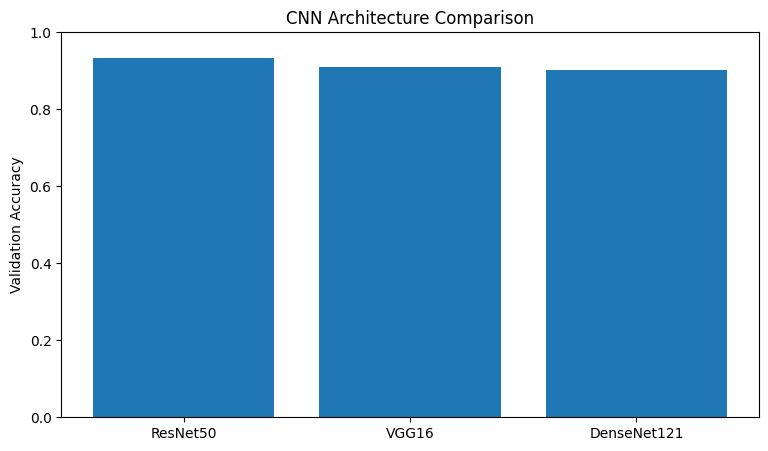

Best architecture: ResNet50


In [24]:

comparison_df = comparison_df.sort_values(
    by="Validation Accuracy",
    ascending=False
)

display(comparison_df)

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Architecture"],
    comparison_df["Validation Accuracy"]
)

plt.ylabel("Validation Accuracy")
plt.title("CNN Architecture Comparison")
plt.ylim(0, 1)
plt.savefig("architecture_comparison.png", dpi=150)
plt.show()

best_architecture = comparison_df.iloc[0]["Architecture"]

print("Best architecture:", best_architecture)


50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 137ms/step
              precision    recall  f1-score   support

      glioma     0.9573    0.6725    0.7900       400
  meningioma     0.7698    0.8025    0.7858       400
     notumor     0.8122    0.9950    0.8944       400
   pituitary     0.9393    0.9675    0.9532       400

    accuracy                         0.8594      1600
   macro avg     0.8697    0.8594    0.8559      1600
weighted avg     0.8697    0.8594    0.8559      1600



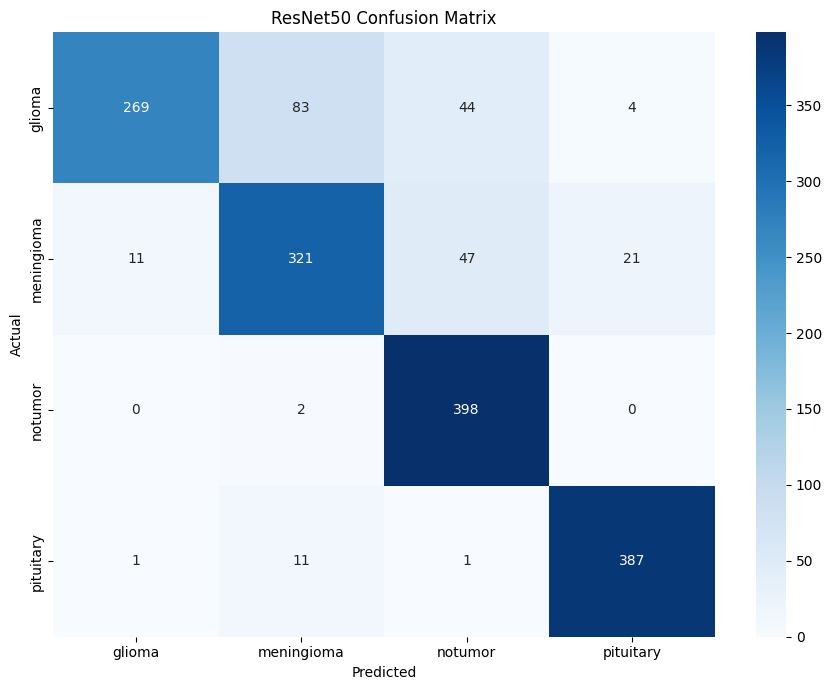

In [25]:

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

best_model = trained_models[best_architecture]

_, preprocess_fn, _ = ARCHITECTURES[best_architecture]

_, _, final_test_ds = prepare_data(preprocess_fn)

y_true = np.concatenate([
    labels.numpy() for images, labels in final_test_ds
])

y_probs = best_model.predict(final_test_ds)
y_pred = np.argmax(y_probs, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{best_architecture} Confusion Matrix")
plt.tight_layout()
plt.savefig("best_model_confusion_matrix.png", dpi=150)
plt.show()


Misclassified glioma images: 131


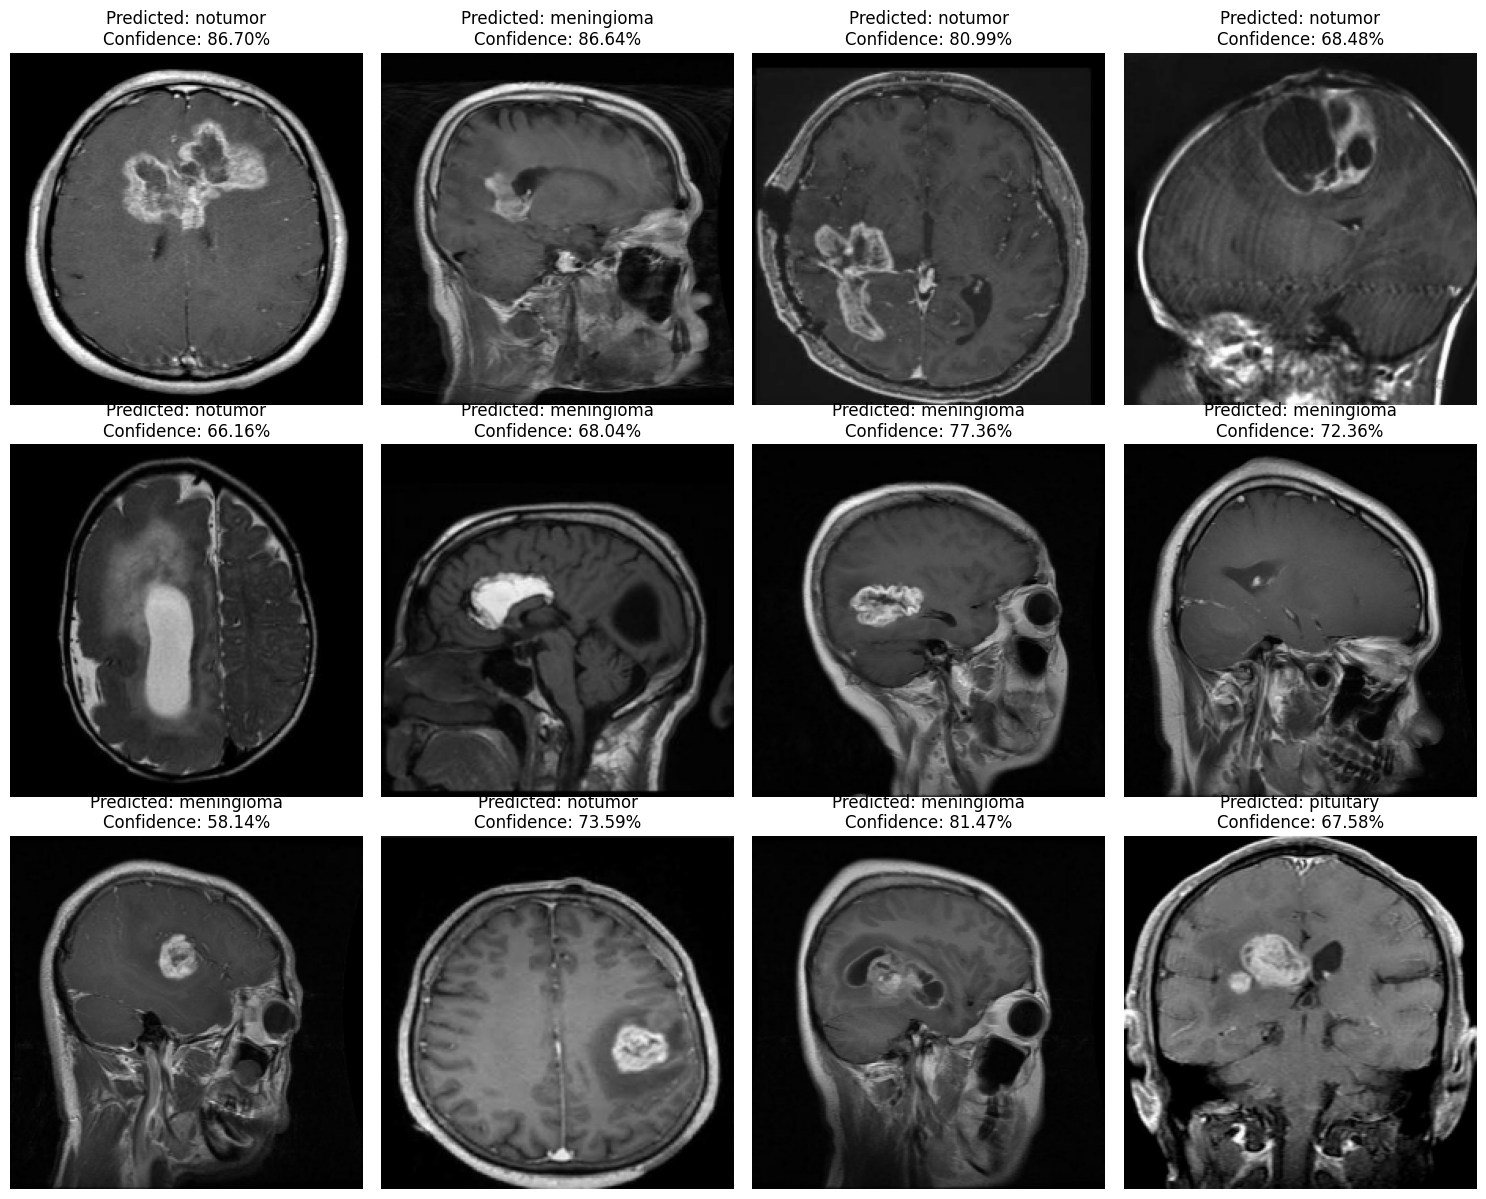

In [26]:

# Get raw test images in the same order as predictions
X_test = np.concatenate([
    images.numpy() for images, labels in test_raw
])

# Actual glioma images incorrectly classified
glioma_idx = class_names.index("glioma")

wrong_glioma = np.where(
    (y_true == glioma_idx) &
    (y_pred != glioma_idx)
)[0]

print("Misclassified glioma images:", len(wrong_glioma))

plt.figure(figsize=(15, 12))

for i, idx in enumerate(wrong_glioma[:12]):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        np.clip(X_test[idx], 0, 255).astype("uint8")
    )

    predicted_class = class_names[y_pred[idx]]
    confidence = y_probs[idx][y_pred[idx]]

    plt.title(
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )

    plt.axis("off")

plt.tight_layout()
plt.savefig("glioma_error_analysis.png", dpi=150)
plt.show()


In [27]:

def generate_gradcam(
    model,
    image,
    architecture,
    class_index=None
):
    base_model = next(
        layer for layer in model.layers
        if isinstance(layer, keras.Model)
    )

    last_conv_name = ARCHITECTURES[architecture][2]

    last_conv_layer = base_model.get_layer(last_conv_name)

    # Outputs convolutional activations and backbone features
    feature_model = keras.Model(
        inputs=base_model.input,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    image = tf.cast(image, tf.float32)
    image = tf.expand_dims(image, axis=0)

    with tf.GradientTape() as tape:

        conv_outputs, backbone_output = feature_model(
            image,
            training=False
        )

        x = backbone_output

        # Apply the classification head
        base_index = model.layers.index(base_model)

        for layer in model.layers[base_index + 1:]:
            x = layer(x, training=False)

        predictions = x

        if class_index is None:
            class_index = tf.argmax(
                predictions[0]
            )

        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + keras.backend.epsilon()
    )

    return heatmap.numpy(), predictions.numpy()[0]


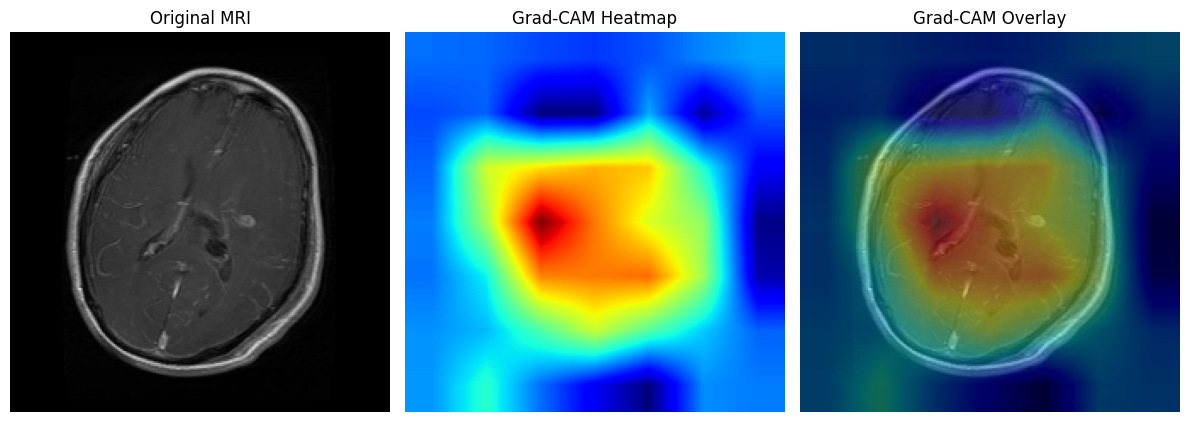

Actual: glioma
Predicted: glioma


In [28]:

import cv2

# Select one correctly classified test image
correct_indices = np.where(y_true == y_pred)[0]

idx = correct_indices[0]

original_image = X_test[idx].astype("uint8")

# Preprocess according to selected architecture
_, preprocess_fn, _ = ARCHITECTURES[best_architecture]

processed_image = preprocess_fn(
    original_image.astype("float32")
)

heatmap, prediction = generate_gradcam(
    best_model,
    processed_image,
    best_architecture
)

heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)

plt.imshow(original_image)
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.4
)

plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.savefig("gradcam_examples.png", dpi=150)
plt.show()

print("Actual:", class_names[y_true[idx]])
print("Predicted:", class_names[np.argmax(prediction)])


In [29]:

best_model = trained_models["ResNet50"]

# Find the pretrained backbone
base_model = next(
    layer for layer in best_model.layers
    if isinstance(layer, keras.Model)
)

base_model.trainable = True

# Unfreeze only the final ResNet stage
for layer in base_model.layers:
    layer.trainable = (
        layer.name.startswith("conv5_")
    )

# Keep BatchNorm layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

best_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

_, resnet_preprocess, _ = ARCHITECTURES["ResNet50"]

train_ds, val_ds, test_ds_final = prepare_data(
    resnet_preprocess
)

fine_history = best_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            patience=2,
            factor=0.2
        )
    ]
)


Epoch 1/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 234ms/step - accuracy: 0.9203 - loss: 0.2193 - val_accuracy: 0.9455 - val_loss: 0.1622 - learning_rate: 1.0000e-05
Epoch 2/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 219ms/step - accuracy: 0.9408 - loss: 0.1643 - val_accuracy: 0.9509 - val_loss: 0.1449 - learning_rate: 1.0000e-05
Epoch 3/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 218ms/step - accuracy: 0.9538 - loss: 0.1286 - val_accuracy: 0.9598 - val_loss: 0.1081 - learning_rate: 1.0000e-05
Epoch 4/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 219ms/step - accuracy: 0.9679 - loss: 0.0957 - val_accuracy: 0.9670 - val_loss: 0.0924 - learning_rate: 1.0000e-05
Epoch 5/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 219ms/step - accuracy: 0.9750 - loss: 0.0757 - val_accuracy: 0.9696 - val_loss: 0.0879 - learning_rate: 1.0000e-05
Epoch 6/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 218ms/step - accuracy: 0.9806 - loss: 0.0573 - val_accuracy: 0.9688 - val_loss: 0.0992 - learning_rate: 1.0000e-05
Epoch 7/8
140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 218ms/ste

In [30]:
test_loss, test_acc = best_model.evaluate(test_ds_final)

print("Final ResNet50 Test Accuracy:", test_acc)

50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 136ms/step - accuracy: 0.9269 - loss: 0.5367
Final ResNet50 Test Accuracy: 0.9268749952316284
